# Module 20 — Evaluating a Vanilla VAE

A low training loss does not by itself show that a VAE generates good samples, uses its latent dimensions, or generalizes. This notebook evaluates a vanilla MNIST VAE across reconstruction, generation, latent behavior, and held-out likelihood. Metrics can disagree, so interpret them together and compare models using the same data, preprocessing, and evaluation protocol.

## Evaluation dimensions

- **Reconstruction:** BCE negative log-likelihood (NLL), MSE, MAE, and visual comparisons.
- **Generation:** samples from the standard normal prior; optionally FID with a fixed feature extractor and preprocessing protocol.
- **Latent behavior:** KL per dimension, active units, and latent traversals. Low KL can indicate underuse, but is not proof a dimension is useless.
- **Generalization and likelihood:** compare training, validation, and held-out test ELBO. ELBO is a lower bound, not the exact log marginal likelihood; an IWAE estimate can provide a tighter bound as K increases in expectation.

Disentanglement scores such as MIG, DCI, SAP, and FactorVAE score generally require known generative factors. Ordinary MNIST labels identify digit class, not the underlying factors such as stroke style, so they are not implemented as disentanglement metrics here.

In [1]:
import math
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

transform = transforms.ToTensor()
full_train = datasets.MNIST('data', train=True, download=True, transform=transform)
test_data = datasets.MNIST('data', train=False, download=True, transform=transform)
train_data, val_data = random_split(full_train, [55000, 5000], generator=torch.Generator().manual_seed(42))
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
train_eval_loader = DataLoader(train_data, batch_size=256, shuffle=False)
val_loader = DataLoader(val_data, batch_size=256, shuffle=False)
test_loader = DataLoader(test_data, batch_size=256, shuffle=False)

class VAE(nn.Module):
    def __init__(self, latent_dim=20):
        super().__init__(); self.latent_dim = latent_dim
        self.encoder = nn.Sequential(nn.Linear(784, 400), nn.ReLU())
        self.fc_mu = nn.Linear(400, latent_dim); self.fc_log_var = nn.Linear(400, latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 400), nn.ReLU(), nn.Linear(400, 784), nn.Sigmoid())
    def encode(self, x):
        h = self.encoder(x.flatten(1)); return self.fc_mu(h), self.fc_log_var(h)
    def reparameterize(self, mu, log_var):
        return mu + torch.exp(0.5 * log_var) * torch.randn_like(mu)
    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)
    def forward(self, x):
        mu, log_var = self.encode(x); return self.decode(self.reparameterize(mu, log_var)), mu, log_var

model = VAE(latent_dim=20).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
print('Device:', device, '| train/validation/test:', len(train_data), len(val_data), len(test_data))

Device: cuda | train/validation/test: 55000 5000 10000


## Train and select using validation ELBO

For Bernoulli pixels, binary cross-entropy is the reconstruction NLL. We sum over pixels and latent dimensions, then average over examples. Use validation ELBO for checkpoint selection; reserve the test set for the final report. The number of epochs is intentionally small for a notebook demonstration.

Epoch 01 | train NELBO 166.17 | validation NELBO 129.50
Epoch 02 | train NELBO 121.88 | validation NELBO 117.51
Epoch 03 | train NELBO 114.90 | validation NELBO 113.54
Epoch 04 | train NELBO 111.86 | validation NELBO 111.41
Epoch 05 | train NELBO 110.05 | validation NELBO 109.69
Epoch 06 | train NELBO 108.90 | validation NELBO 108.98
Epoch 07 | train NELBO 107.97 | validation NELBO 108.02
Epoch 08 | train NELBO 107.27 | validation NELBO 107.53
Epoch 09 | train NELBO 106.70 | validation NELBO 106.93
Epoch 10 | train NELBO 106.28 | validation NELBO 106.75
Epoch 11 | train NELBO 105.87 | validation NELBO 106.41
Epoch 12 | train NELBO 105.59 | validation NELBO 106.18
Epoch 13 | train NELBO 105.30 | validation NELBO 105.83
Epoch 14 | train NELBO 105.08 | validation NELBO 105.59
Epoch 15 | train NELBO 104.80 | validation NELBO 105.43
Epoch 16 | train NELBO 104.62 | validation NELBO 105.41
Epoch 17 | train NELBO 104.39 | validation NELBO 105.07
Epoch 18 | train NELBO 104.28 | validation NELBO

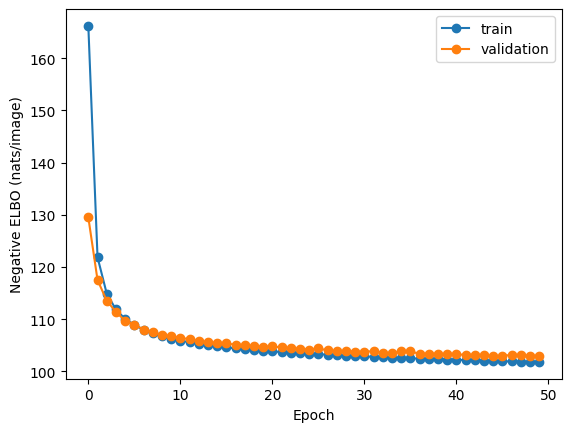

In [2]:
def elbo_terms(x, reconstruction, mu, log_var):
    nll = F.binary_cross_entropy(reconstruction, x, reduction='none').flatten(1).sum(1)
    kl_dim = 0.5 * (mu.square() + log_var.exp() - 1 - log_var)
    kl = kl_dim.sum(1)
    return nll, kl, kl_dim

def mean_elbo(loader, training=False):
    model.train(training); total = 0.0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for x, _ in loader:
            x = x.to(device)
            if training: optimizer.zero_grad()
            recon, mu, log_var = model(x)
            nll, kl, _ = elbo_terms(x, recon, mu, log_var)
            loss = (nll + kl).mean()
            if training:
                loss.backward(); optimizer.step()
            total += loss.item() * x.size(0)
    return total / len(loader.dataset)

epochs = 50
history = {'train': [], 'validation': []}
best_validation = float('inf'); best_state = None
for epoch in range(1, epochs + 1):
    train_nelbo = mean_elbo(train_loader, training=True)
    val_nelbo = mean_elbo(val_loader)
    history['train'].append(train_nelbo); history['validation'].append(val_nelbo)
    if val_nelbo < best_validation:
        best_validation = val_nelbo
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    print(f'Epoch {epoch:02d} | train NELBO {train_nelbo:.2f} | validation NELBO {val_nelbo:.2f}')
model.load_state_dict(best_state)
plt.plot(history['train'], marker='o', label='train'); plt.plot(history['validation'], marker='o', label='validation')
plt.xlabel('Epoch'); plt.ylabel('Negative ELBO (nats/image)'); plt.legend(); plt.show()

## Held-out reconstruction and likelihood metrics

Report test NLL and KL separately as well as the negative ELBO. MSE and MAE are pixel-space distortion measures, not substitutes for the model's likelihood. Reconstructions below use the posterior mean for a stable visual comparison; the NLL/ELBO evaluation uses a sampled latent value.

In [4]:
@torch.no_grad()
def evaluate_reconstruction(loader):
    model.eval(); sums = torch.zeros(5); count = 0
    kl_dimensions = torch.zeros(model.latent_dim); mu_values = []
    for x, _ in loader:
        x = x.to(device); recon, mu, log_var = model(x)
        nll, kl, kl_dim = elbo_terms(x, recon, mu, log_var)
        mse = (x - recon).square().flatten(1).mean(1)
        mae = (x - recon).abs().flatten(1).mean(1)
        sums += torch.tensor([nll.sum().item(), kl.sum().item(), mse.sum().item(), mae.sum().item(), (nll + kl).sum().item()])
        kl_dimensions += kl_dim.sum(0).cpu(); mu_values.append(mu.cpu()); count += x.size(0)
    return {'nll': sums[0].item()/count, 'kl': sums[1].item()/count, 'mse': sums[2].item()/count, 'mae': sums[3].item()/count, 'nelbo': sums[4].item()/count, 'kl_per_dim': kl_dimensions/count, 'mu': torch.cat(mu_values)}

train_metrics = evaluate_reconstruction(train_eval_loader)
val_metrics = evaluate_reconstruction(val_loader)
test_metrics = evaluate_reconstruction(test_loader)
for name, metrics in [('train', train_metrics), ('validation', val_metrics), ('test', test_metrics)]:
    print(f'{name:10s} | NLL {metrics["nll"]:.2f} | KL {metrics["kl"]:.2f} | NELBO {metrics["nelbo"]:.2f} | MSE {metrics["mse"]:.5f} | MAE {metrics["mae"]:.5f}')

train      | NLL 76.21 | KL 25.50 | NELBO 101.71 | MSE 0.01169 | MAE 0.03775
validation | NLL 77.53 | KL 25.50 | NELBO 103.03 | MSE 0.01220 | MAE 0.03858
test       | NLL 76.68 | KL 25.44 | NELBO 102.12 | MSE 0.01194 | MAE 0.03794


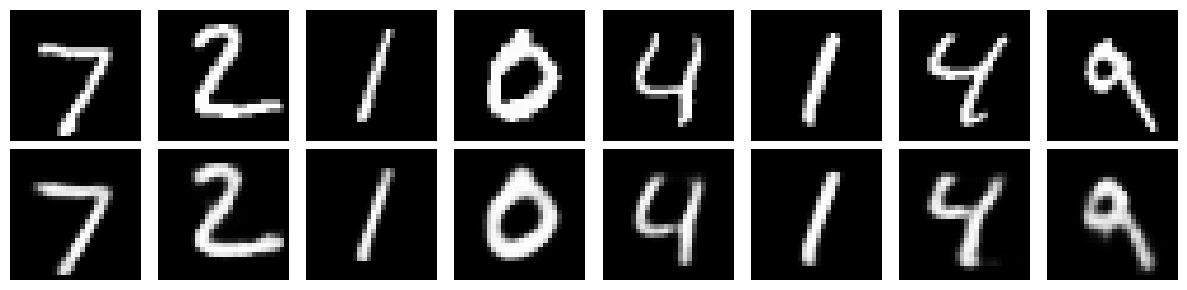

In [7]:
images, _ = next(iter(test_loader)); images = images[:8].to(device)
model.eval()
with torch.no_grad(): mu, _ = model.encode(images); recon_mean = model.decode(mu)
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    axes[0, i].imshow(images[i, 0].cpu(), cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(recon_mean[i, 0].cpu(), cmap='gray'); axes[1, i].axis('off')
axes[0, 0].set_ylabel('Input'); axes[1, 0].set_ylabel('Posterior mean')
plt.tight_layout(); plt.show()

## Latent diagnostics: KL and active units

Average KL near zero suggests a dimension stays close to the prior and may carry little input-specific information. Active units are defined here by variance of posterior means across examples greater than `active_threshold`. That count depends on the threshold and does not measure semantic quality.

Active latent units: 20 / 20 (variance threshold 0.01)


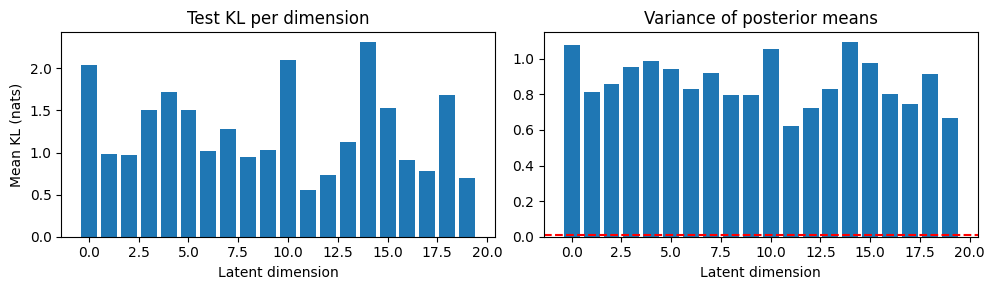

In [9]:
kl_per_dim = test_metrics['kl_per_dim']
mu_test = test_metrics['mu']
active_threshold = 0.01
mu_variance = mu_test.var(dim=0, unbiased=False)
active = mu_variance > active_threshold
print(f'Active latent units: {active.sum().item()} / {model.latent_dim} (variance threshold {active_threshold})')
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].bar(range(model.latent_dim), kl_per_dim.numpy()); axes[0].set(title='Test KL per dimension', xlabel='Latent dimension', ylabel='Mean KL (nats)')
axes[1].bar(range(model.latent_dim), mu_variance.numpy()); axes[1].axhline(active_threshold, color='red', linestyle='--'); axes[1].set(title='Variance of posterior means', xlabel='Latent dimension')
plt.tight_layout(); plt.show()

## Prior samples and latent traversal

Prior samples assess generation rather than reconstruction. Look for artifacts, repetition, and limited diversity. A traversal varies one coordinate while holding the rest fixed; smooth changes are useful diagnostics but do not prove disentanglement.

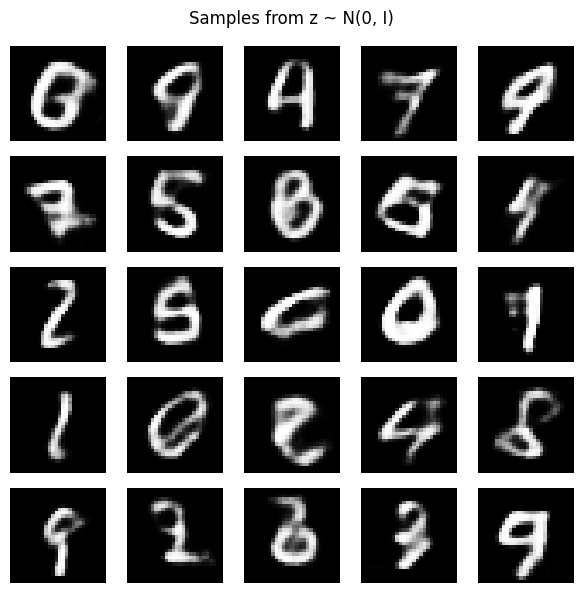

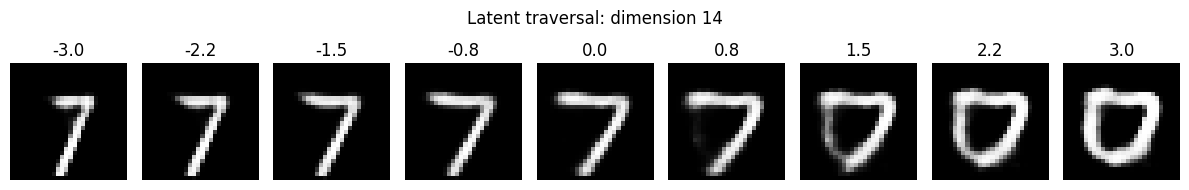

In [11]:
with torch.no_grad():
    prior_samples = model.decode(torch.randn(25, model.latent_dim, device=device)).cpu()
fig, axes = plt.subplots(5, 5, figsize=(6, 6))
for ax, image in zip(axes.flat, prior_samples):
    ax.imshow(image[0], cmap='gray'); ax.axis('off')
plt.suptitle('Samples from z ~ N(0, I)'); plt.tight_layout(); plt.show()

base = mu_test[0].to(device).unsqueeze(0)
dimension = int(torch.argmax(kl_per_dim).item())
values = torch.linspace(-3, 3,  nine := 9, device=device)
z_grid = base.repeat(nine, 1); z_grid[:, dimension] = values
with torch.no_grad(): traversals = model.decode(z_grid).cpu()
fig, axes = plt.subplots(1, nine, figsize=(12, 2))
for ax, image, value in zip(axes, traversals, values.cpu()):
    ax.imshow(image[0], cmap='gray'); ax.set_title(f'{value:.1f}'); ax.axis('off')
plt.suptitle(f'Latent traversal: dimension {dimension}'); plt.tight_layout(); plt.show()

## Tighter held-out likelihood bound with IWAE

The following estimates an IWAE bound using K posterior samples per input. This is still a lower bound, not exact marginal likelihood. Increasing K tightens the bound in expectation but costs more compute and can make individual finite-sample estimates noisy.

In [12]:
@torch.no_grad()
def estimate_iwae(loader, K=20):
    model.eval(); total = 0.0
    for x, _ in loader:
        x = x.to(device); mu, log_var = model.encode(x); std = torch.exp(0.5 * log_var)
        z = mu.unsqueeze(0) + std.unsqueeze(0) * torch.randn(K, *mu.shape, device=device)
        flat_z = z.reshape(-1, model.latent_dim); recon = model.decode(flat_z).view(K, x.size(0), 1, 28, 28)
        xk = x.unsqueeze(0).expand_as(recon)
        log_px_z = -F.binary_cross_entropy(recon, xk, reduction='none').flatten(2).sum(2)
        log_pz = -0.5 * (math.log(2 * math.pi) + z.square()).sum(2)
        log_qz_x = -0.5 * (math.log(2 * math.pi) + log_var.unsqueeze(0) + (z - mu.unsqueeze(0)).square() / log_var.exp().unsqueeze(0)).sum(2)
        log_w = log_px_z + log_pz - log_qz_x
        bound = torch.logsumexp(log_w, dim=0) - math.log(K)
        total += bound.sum().item()
    return total / len(loader.dataset)

for K in [1, 5, 20]:
    print(f'Test IWAE bound, K={K:2d}: {estimate_iwae(test_loader, K):.2f} nats/image')

Test IWAE bound, K= 1: -102.14 nats/image
Test IWAE bound, K= 5: -99.81 nats/image
Test IWAE bound, K=20: -98.80 nats/image


## Optional FID for MNIST

FID compares feature distributions from real and generated images; lower is generally better only under a fixed protocol. Standard Inception FID is designed for natural images, so values on resized grayscale MNIST are not directly comparable with published natural-image FID. This optional cell requires `torchmetrics[image]` and `torch-fidelity` plus its feature weights. If dependencies or downloads are unavailable, use the prior samples and other metrics instead. Always state the feature extractor, image preprocessing, and sample count.

In [ ]:
# !pip install torchmetrics[image]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.6/85.6 kB 999.6 kB/s eta 0:00:000:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 5.2 MB/s eta 0:00:00a 0:00:01


In [15]:
# Optional: install torchmetrics[image] and torch-fidelity in your environment before running.
try:
    from torchmetrics.image.fid import FrechetInceptionDistance
    fid = FrechetInceptionDistance(feature=64, normalize=False).to(device)
    @torch.no_grad()
    def to_fid_uint8(images):
        rgb = images.repeat(1, 3, 1, 1)
        rgb = F.interpolate(rgb, size=(299, 299), mode='bilinear', align_corners=False)
        return (rgb.clamp(0, 1) * 255).to(torch.uint8)
    fid_count = 1000
    used = 0
    for x, _ in test_loader:
        if used >= fid_count: break
        x = x[:fid_count-used].to(device); fid.update(to_fid_uint8(x), real=True); used += x.size(0)
    generated = []
    while sum(t.size(0) for t in generated) < fid_count:
        n = min(128, fid_count - sum(t.size(0) for t in generated))
        with torch.no_grad(): generated.append(model.decode(torch.randn(n, model.latent_dim, device=device)).cpu())
    fake = torch.cat(generated).to(device)
    fid.update(to_fid_uint8(fake), real=False)
    print(f'Approximate MNIST FID ({fid_count} real and generated images, Inception features): {fid.compute().item():.2f}')
except (ImportError, ModuleNotFoundError) as error:
    print('Optional FID dependencies are not installed:', error)

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 211MB/s]


Approximate MNIST FID (1000 real and generated images, Inception features): 0.05


## Reading results and limitations

A practical dashboard reports held-out reconstruction NLL, MSE/MAE, ELBO or IWAE bound, per-dimension KL, active units with the threshold, and prior-sample images. Add FID or precision/recall only when their feature space and protocol fit the dataset. Pixel metrics can penalize small shifts; visual inspection exposes artifacts and diversity failures that aggregate scores hide. A model can reconstruct well and still sample poorly if the aggregate encoded distribution is poorly matched to the prior.

For representation studies, MIG, DCI, SAP, and FactorVAE score need suitable factor labels and do not guarantee downstream usefulness. For classification, evaluate the frozen or fine-tuned representation in a controlled downstream task. For compression, report rate-distortion behavior. Choose metrics for the project goal rather than calculating every available metric.